# 第3章 Matplotlib で図を描く ―― 二色の交流を見てみる

**この章でできるようになること**
- `fig, ax = plt.subplots()` の形で図を描ける
- 軸ラベル・凡例・目盛り・格子・対数軸を付けられる
- 図を並べたり、2次元の表をカラーマップで描いたりできる
- 図をファイル（PNG）に保存できる

**例え：** `fig`（Figure）は**画用紙**、`ax`（Axes）は画用紙に貼った**グラフ用紙**です。1枚の画用紙に何枚もグラフ用紙を貼れます。線を引くのはいつもグラフ用紙（`ax`）に対してです。

| 用語 | 意味 | 例え |
|---|---|---|
| Matplotlib | Python で図を描く定番のライブラリ | 製図道具一式 |
| Figure（fig） | 図全体の入れ物 | 画用紙 |
| Axes（ax） | 軸のついた1つのグラフ | 画用紙に貼ったグラフ用紙 |
| 凡例（legend） | どの線が何かを示す説明 | 地図の記号の説明欄 |
| カラーマップ | 数の大きさを色で表すもの | 天気図の気温の色分け |
| うなり | 周波数の近い2つの波を足すと、振幅がゆっくり大きくなったり小さくなったりすること | 2つの音叉を同時に鳴らすと「ワンワン」と聞こえる |
| 共通周期 | 2つの周期的な動きが、そろって最初に戻るまでの時間 | 5拍子と8拍子の頭がそろう40拍 |

> 研究コードとのつながり：`py/figures.py` は `fig,ax=plt.subplots(1,2,...)`、`ax.set_xscale('log')`、`fig.savefig(FIGS/'Fig1_....png',dpi=150)` の形で図を作っています。
>
> 図の文字は、どの計算機でも文字化けしないように英語と記号で書きます。

In [1]:
# 準備：教材の部品（kyozai/）を import できるようにする。どの章でも最初に1回だけ実行する。
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "kyozai").exists():   # kyozai/ があるフォルダまで上にたどる
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("教材の場所:", ROOT.name)

教材の場所: python-from-my-research


## 3.1 一番かんたんな図

研究の駆動項 A(sin Ω₁τ + sin Ω₂τ) を描きます。

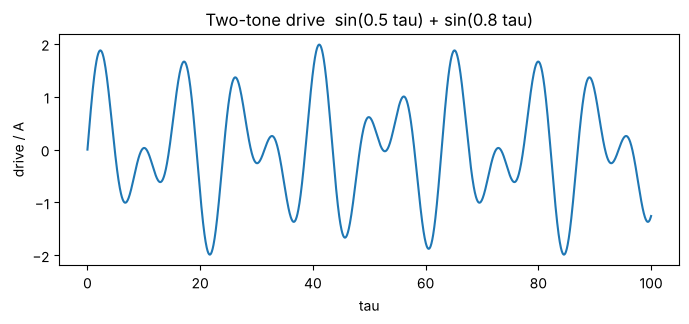

In [2]:
import numpy as np
import matplotlib.pyplot as plt

O1, O2, A = 0.5, 0.8, 1.0
tau = np.linspace(0, 100, 2000)
drive = A * (np.sin(O1 * tau) + np.sin(O2 * tau))

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(tau, drive)
ax.set_xlabel("tau")
ax.set_ylabel("drive / A")
ax.set_title("Two-tone drive  sin(0.5 tau) + sin(0.8 tau)")
plt.show()

## 3.2 いくつも重ねる・凡例・格子

2つの成分と、その和を重ねます。`label=` を付けて `ax.legend()` を呼ぶと凡例が出ます。

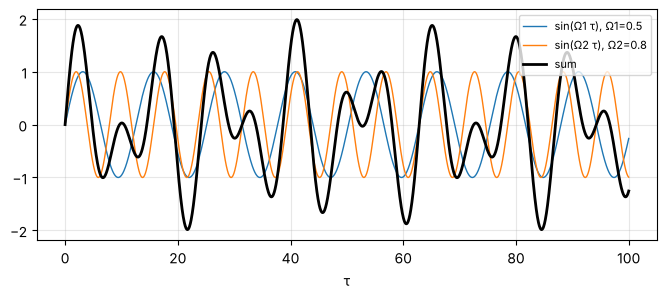

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(tau, np.sin(O1 * tau), lw=1, label="sin(Ω1 τ), Ω1=0.5")
ax.plot(tau, np.sin(O2 * tau), lw=1, label="sin(Ω2 τ), Ω2=0.8")
ax.plot(tau, drive, "k", lw=2, label="sum")
ax.set_xlabel("τ"); ax.legend(loc="upper right", fontsize=8); ax.grid(alpha=0.3)
plt.show()

## 3.3 共通周期を確かめる

Ω₁ = 0.5 の周期は 2π/0.5 = 4π、Ω₂ = 0.8 の周期は 2π/0.8 = 2.5π です。4π × 5 = 2.5π × 8 = 20π なので、**τ = 20π ごとに和の波形がまったく同じにくり返す**はずです。図で確かめます。

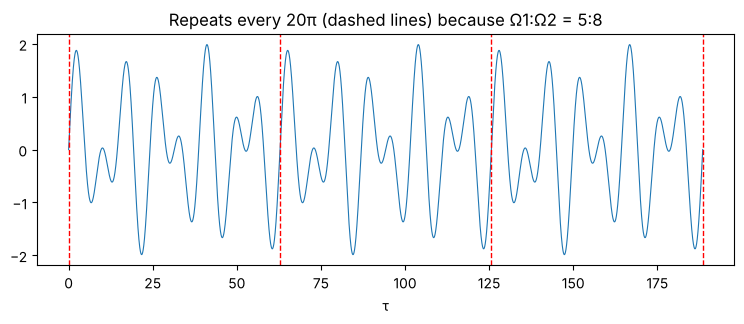

True


In [4]:
T = 20 * np.pi
tau = np.linspace(0, 3 * T, 6000)
drive = np.sin(O1 * tau) + np.sin(O2 * tau)

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(tau, drive, lw=0.8)
for j in range(4):
    ax.axvline(j * T, color="r", ls="--", lw=1)   # 縦の補助線
ax.set_xlabel("τ"); ax.set_title("Repeats every 20π (dashed lines) because Ω1:Ω2 = 5:8")
plt.show()

# 数でも確かめる：τ と τ+20π で値が同じか
t0 = np.linspace(0, T, 500)
print(np.allclose(np.sin(O1*t0) + np.sin(O2*t0), np.sin(O1*(t0+T)) + np.sin(O2*(t0+T))))

Ω₂ = 0.81 にすると 0.5:0.81 = 50:81 となり、共通周期はとても長くなります（200π）。研究の反実験（第9章）で、この「ずらし」を使います。

## 3.4 図を並べる（subplots）

`plt.subplots(行, 列)` で何枚も並べられます。`ax` は配列になり、`ax[0]`、`ax[1]` で選びます。`sharey=True` は縦軸の範囲をそろえる指定です。

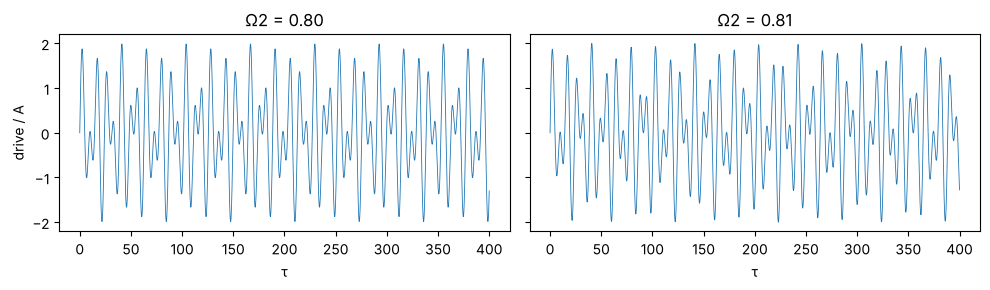

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for j, O2x in enumerate([0.80, 0.81]):
    tau = np.linspace(0, 400, 8000)
    ax[j].plot(tau, np.sin(O1 * tau) + np.sin(O2x * tau), lw=0.6)
    ax[j].set_title(f"Ω2 = {O2x:.2f}")
    ax[j].set_xlabel("τ")
ax[0].set_ylabel("drive / A")
fig.tight_layout()     # 文字が重ならないように自動で間隔を調整
plt.show()

## 3.5 ステップの電圧を図にする

第1章の V = nΩ₁ + mΩ₂ を、横軸 n・縦軸 m の平面に色で描きます。`scatter` の `c=` に値を渡すと色分けされ、`colorbar` で色の目盛りが付きます。

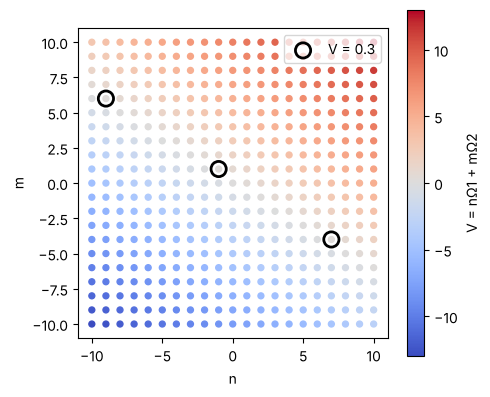

In [6]:
nn, mm = np.meshgrid(np.arange(-10, 11), np.arange(-10, 11))   # 格子状の (n, m)
VV = nn * O1 + mm * O2
on_03 = np.isclose(VV, 0.3)

fig, ax = plt.subplots(figsize=(5, 4.5))
sc = ax.scatter(nn, mm, c=VV, cmap="coolwarm", s=18)
ax.scatter(nn[on_03], mm[on_03], s=120, facecolors="none", edgecolors="k", lw=2, label="V = 0.3")
fig.colorbar(sc, ax=ax, label="V = nΩ1 + mΩ2")
ax.set_xlabel("n"); ax.set_ylabel("m"); ax.legend(loc="upper right")
ax.set_aspect("equal")
plt.show()

丸で囲んだ点 (−9, 6)、(−1, 1)、(7, −4) が、**同じ電圧 0.3 に並んでいる**ことが見えます。

`np.meshgrid` は MATLAB の `meshgrid` と同じで、2つの1次元配列から格子状の2次元配列を作ります。

## 3.6 2次元の表を色で描く（pcolormesh）

研究の IV マップ `V[電流, 振幅]` は `ax.pcolormesh(A, I, V)` で描けます（第6章で本物を描きます）。ここでは仮の表で練習します。

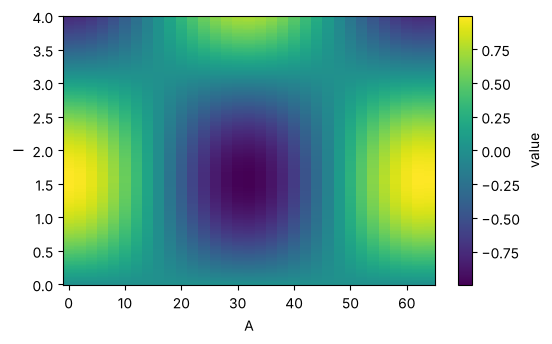

In [7]:
I = np.linspace(0, 4, 200)
A = np.linspace(0, 64, 33)
fake = np.sin(I[:, None]) * np.cos(A[None, :] / 10)   # 仮の表。形 (200, 33)

fig, ax = plt.subplots(figsize=(6, 3.5))
pc = ax.pcolormesh(A, I, fake, shading="auto", cmap="viridis")
fig.colorbar(pc, ax=ax, label="value")
ax.set_xlabel("A"); ax.set_ylabel("I")
plt.show()

`pcolormesh(横, 縦, 表)` の表の形は **(縦の数, 横の数)** です。IV マップは (電流, 振幅) なので、横が A、縦が I になります。

## 3.7 対数軸と保存

`ax.set_xscale("log")` で対数軸になります。研究の図1では横軸の β を対数にしています。`fig.savefig("名前.png", dpi=150)` で保存します。

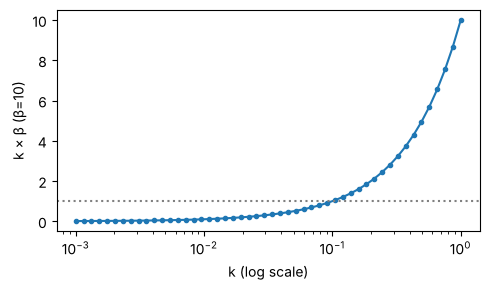

保存した: scratch/ch03_log_axis.png


In [8]:
from kyozai.paths import ROOT
outdir = ROOT / "scratch"          # 練習用の出力フォルダ（.gitignore で無視される）
outdir.mkdir(exist_ok=True)

k = np.logspace(-3, 0, 50)         # 0.001〜1 を対数で等間隔に 50 点
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(k, k * 10, "o-", ms=3)
ax.set_xscale("log"); ax.set_xlabel("k (log scale)"); ax.set_ylabel("k × β (β=10)")
ax.axhline(1, color="gray", ls=":")
fig.tight_layout()
fig.savefig(outdir / "ch03_log_axis.png", dpi=150)
plt.show()
print("保存した:", (outdir / "ch03_log_axis.png").relative_to(ROOT))

## 練習問題

1. 3.3 の図を Ω₂ = 0.81 で描き、共通周期 200π ごとに縦線を引いてください（τ は 0〜3×200π）。
2. 3.5 の図に、V = 0.8（ステップ (0,1) の電圧）に届く点も、別の色の丸で重ねてください。

<details><summary>答え</summary>

```python
# 1.
T2 = 200 * np.pi
tau = np.linspace(0, 3 * T2, 30000)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(tau, np.sin(0.5 * tau) + np.sin(0.81 * tau), lw=0.4)
for j in range(4):
    ax.axvline(j * T2, color="r", ls="--")
plt.show()
# 2.
on_08 = np.isclose(VV, 0.8)
# 3.5 のセルに次の1行を足す
# ax.scatter(nn[on_08], mm[on_08], s=120, facecolors="none", edgecolors="g", lw=2, label="V = 0.8")
```
</details>

## まとめ
- 図は `fig, ax = plt.subplots()` で始め、線は `ax.plot`、文字は `ax.set_xlabel` など `ax` に対して描く。
- Ω₁:Ω₂ = 5:8 の二色の波形は、τ = 20π ごとにまったく同じにくり返す。
- 2次元の表は `pcolormesh(横, 縦, 表)`。表の形は (縦の数, 横の数)。